## Step 1: Welcoming our Data :D

Let's test run a line of code to make sure everything is working!

In [1]:
print("Hello, tiny space travelers!")

Hello, tiny space travelers!


## Step 2: Load and preview our data

We will load a table prepared from NASA’s OSD-964 yeast radiation dataset.

These experiments were conducted on Earth using radiation exposure.
Our classroom CSV contains selected raw measurements from both yeast strains
during hours 0-24.

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/KimiyaTrevino/tiny-space-travelers/main/Yeast%20Radiation%20Data.csv"

data = pd.read_csv(url)

data.head()

,strain,dose_gy,time_hours,replicate,well,absorbance_570nm,absorbance_600nm
0,rad51_delta,0.00,0,1,A1,0.342,0.453
1,rad51_delta,0.01,0,1,A2,0.340,0.451
2,rad51_delta,0.05,0,1,A3,0.345,0.459
3,rad51_delta,0.10,0,1,A4,0.331,0.439
4,rad51_delta,0.35,0,1,A5,0.343,0.456


### What did we just do?

- `import pandas as pd` loads our tool for working with tables.
- `url` stores the web address of the CSV.
- `pd.read_csv(url)` loads the CSV into a table named `data`.
- `data.head()` displays only the first five rows-not the whole dataset.

### How do we read this table?

Each row represents one sample well measured at one time.

For example, the first row shows:
- **Strain:** `rad51_delta` - yeast missing the RAD51 gene.
- **Dose:** 0 Gy - no added radiation exposure.
- **Time:** Hour 0 - the beginning of the measurement series.
- **Replicate:** 1 - the first repeated sample.
- **Well:** A1 - the sample’s position on the plate.

The absorbance columns contain raw light measurements,
not direct counts of yeast cells.
- The label 570 nm - A wavelength useful for detecting the pink, chemically changed form of the dye
- The label 600 nm - A wavelength useful for detecting the blue, original form
- Nanometers (nm): a unit used to describe light’s wavelength
- A reading like 0.342 - An absorbance value, not 342 cells or 34.2% activity. It's radiation energy **absorbed** during the treatment.

The numbers on the far left (0, 1, 2...) are pandas row labels.
They are not experimental measurements.

### **Think about it**

We only see `rad51_delta` in this preview.
**Does that mean wild-type yeast is missing; or might it appear farther down?**

Answer: Wild-type yeast is not missing, it appears farther down! head() only shows the first five rows. When we run unique(), Python checks the entire strain column and lists each different strain name once. Our result confirms both strains are present. We usually do this so there's not 1000+ data points on our screen but we can see a general overview so we can study the data later on!

In [3]:
data["strain"].unique()

array(['rad51_delta', 'wild_type'], dtype=object)

## Step 3: Choose a radiation dose

We’ll start with 0 Gy: samples with no added radiation exposure. (Only show me samples that received no added radiation (filtering!))

This lets us explore the two strains before comparing radiation treatments.

`data["dose_gy"] == 0` checks which rows have a dose of zero.
The outer brackets keep only those rows.

We store the selected rows in a new table called `control` for this "filtered" table.
The original `data` table stays unchanged.

In [7]:
control = data[data["dose_gy"] == 0]

control.head()

,strain,dose_gy,time_hours,replicate,well,absorbance_570nm,absorbance_600nm
0,rad51_delta,0.0,0,1,A1,0.342,0.453
12,rad51_delta,0.0,0,2,B1,0.336,0.446
24,rad51_delta,0.0,0,3,C1,0.342,0.456
45,rad51_delta,0.0,1,1,A1,0.337,0.446
57,rad51_delta,0.0,1,2,B1,0.335,0.442


## Step 4: Make our first graph

We will plot the raw 570 nm absorbance readings over time at 0 Gy.

There are three repeated samples for each strain at each time.
We’ll average those readings to draw one line per strain.

### What does the code do?

- `import matplotlib.pyplot as plt` loads a graphing tool.
- `groupby()` groups readings by strain and time.
- `mean()` calculates the average absorbance for each group.
- `unstack()` places each strain in a separate column.
- `plot()` draws the lines.
- `plt.show()` displays the graph.

### Read the graph

- Horizontal axis: measurement time in hours.
- Vertical axis: average raw absorbance at 570 nm.
- Each line: one yeast strain.

This graph shows instrument readings (the setup!), not cell counts.

The 0 we selected means 0 Gy radiation dose, not hour 0.
So the graph shows both yeast strains over 24 hours, with no added radiation exposure. (Basically a baseline reading)!


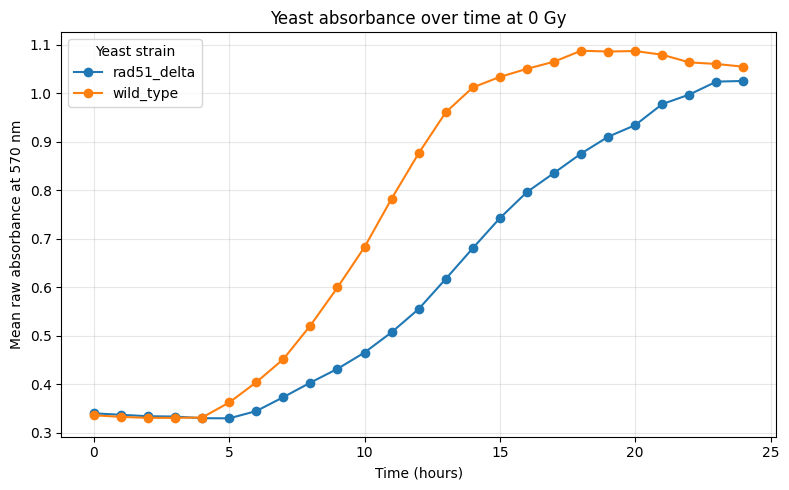

In [8]:
import matplotlib.pyplot as plt

averages = control.groupby(
    ["time_hours", "strain"]
)["absorbance_570nm"].mean().unstack()

averages.plot(figsize=(8, 5), marker="o")

plt.title("Yeast absorbance over time at 0 Gy")
plt.xlabel("Time (hours)")
plt.ylabel("Mean raw absorbance at 570 nm")
plt.legend(title="Yeast strain")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### **Discuss: What does this graph tell us?**

**Students may say: “The line rises, so there is more yeast.”**

What we can actually say:
The sample absorbed more light at 570 nm.
This measurement alone does not directly tell us how many yeast cells are present.

**Students may say: “The line falls, so the yeast is dying.”**

What we can actually say:
The absorbance reading decreased.
That alone does not prove cells died. The dye changes as cells react with it,
and its response depends on the measurement wavelength.

**Students may say: “The lines separate, so one strain is healthier.”**

What we can actually say:
The strains have different average absorbance readings at that time.
To explain why, we would need to consider assay processing,
variation among repeated samples, and differences between the plates.

**Students may say: “This proves radiation affected the yeast.”**

What we can actually say:
This graph only includes 0 Gy samples, neither group received added radiation.
We need to compare radiation-treated samples with their matching 0 Gy controls
to investigate a radiation response.

Note:
- Higher number: more of that light was absorbed.
- Lower number: less of that light was absorbed.
- Average: we combined the three repeated samples for that strain at that hour.

### Our takeaway

Describe what the graph measures before explaining what it might mean.

“I observe ______ in the absorbance readings.
This could suggest ______, but this graph alone does not prove it.”

## Step 5: Compare radiation treatments (The Fun part!)

Now we’ll compare samples that received 10 Gy with samples that received
no added radiation (0 Gy).

Each panel shows one yeast strain.
Each line shows the average raw absorbance at 570 nm for one dose.

Compare the two doses within each panel:
- Do their readings follow similar patterns?
- When do the lines begin to differ?

These are raw instrument readings. This graph helps us explore a possible
radiation response, but does not directly measure survival or cell numbers.

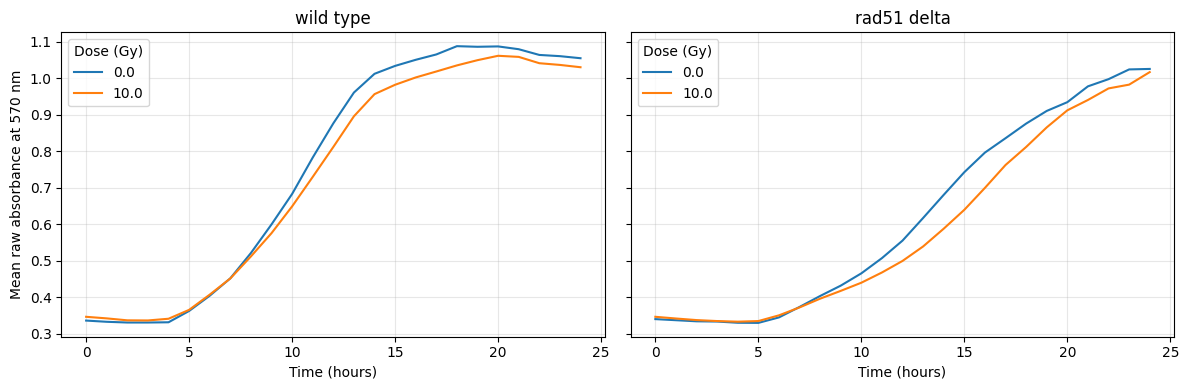

In [12]:
comparison = data[data["dose_gy"].isin([0, 10])]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, strain in zip(axes, ["wild_type", "rad51_delta"]):
    subset = comparison[comparison["strain"] == strain]

    means = subset.groupby(
        ["time_hours", "dose_gy"]
    )["absorbance_570nm"].mean().unstack()

    means.plot(ax=ax)
    ax.set_title(strain.replace("_", " "))
    ax.set_xlabel("Time (hours)")
    ax.set_ylabel("Mean raw absorbance at 570 nm")
    ax.legend(title="Dose (Gy)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Baseline is blue line (0) (remember, this has nothing added, just a baseline to study it's "natural state".)
# The Added Gy is the orange line (10) (remember, we added a small dose to see the difference from baseline!)

**So, do the readings change when we give the yeast radiation?**

Yes! In both panels, the radiation-treated samples have lower average absorbance at 570 nm than the untreated samples during parts of the experiment.

That means the machine detected a different light-absorption pattern in the yeast-and-dye mixture after radiation treatment.

This is evidence of a change in the measured response. It does not directly tell us how many cells died or how much DNA was repaired.

To compare the strains, look at how each strain’s radiation-treated line differs from its own untreated line.

----

Our graph shows that radiation-treated and untreated samples have different absorbance patterns.

**This gives us a new research question: Does the pattern change as radiation dose increases?**

We could explore additional doses and check whether the differences are consistent across repeated samples. Researchers can also process both light measurements and use other tests to investigate cellular activity, survival, and DNA damage.

These graphs help us generate questions. They don’t yet prove that either strain can “fight off” radiation.

----

## Your research conclusion

Complete these three sentences:

1. I predicted ______.
2. At 10 Gy compared with 0 Gy, I observed ______ in the absorbance readings.
3. One thing this graph cannot tell us is ______.

----

## Spoilers on this research!

The full study found that increasing radiation dose reduced yeast growth and metabolic activity—and the yeast missing RAD51 was affected more strongly than wild type. data.nasa.gov
So the takeaway is: having that DNA repair gene helps yeast cope with radiation damage.

## But...

It helps NASA study how living cells cope with space radiation—and how DNA repair affects that response.

This can guide research into:
- Radiation risks: how different doses affect cells.
- Biological sensors: using yeast’s response to detect radiation’s biological effects.
- Astronaut protection: providing evidence for further studies on reducing harm during long missions.

NASA specifically describes this study as informing improved biosensors for future deep-space missions.

**Small research like this can gives NASA a small, manageable way to investigate a big question: how does space radiation affect living things?**

----

## What you accomplished

You used Python to load NASA-derived data, inspect a table,
select samples, calculate averages, and create graphs!

Optional challenge:
Replace 10 with another dose in the dataset and rerun the comparison.

### 💡 Hint!

Look at the first line of the Step 5 code:

comparison = data[data["dose_gy"].isin([0, 10])]

The numbers inside `[0, 10]` choose the two doses to compare.

Keep **0** as your untreated comparison. Replace **10** with another
dose in the dataset, such as **20**, then rerun the whole code cell.

What changes in the graph?